# Projeto Predição de taxas de Juros

**Descrição:** Este projeto analisa dados de solicitações e operações de financiamento imobiliário referentes a imóveis localizados na Carolina do Norte, Estados Unidos, em 2025. Os dados são coletados no âmbito da Home Mortgage Disclosure Act (HMDA) e disponibilizados publicamente na plataforma HMDA do FFIEC.

**Objetivo:** 
- Desenvolver e avaliar modelos de regressão para estimar a taxa de juros observada em financiamentos imobiliários com base nas características da operação.
- Estruturar as etapas de exploração, tratamento dos dados e modelagem como base para uma futura aplicação end-to-end, abrangendo desde a obtenção dos dados até a disponibilização das previsões.

**Disponível em:** [HMDA](https://ffiec.cfpb.gov/)

**Descrição dos dados:** O conjunto de dados completo, os códigos das categorias e os valores especiais podem ser consultados no [dicionário oficial de dados da HMDA](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields).
| Variável | Descrição | Tipo / Unidade |
| :---: | :--- | :--- |
| `interest_rate` | Taxa de juros anual do financiamento. **Variável alvo do modelo.** | Numérica — % |
| `loan_amount` | Valor do financiamento. | Numérica — US$ |
| `income` | Renda bruta anual considerada na decisão de crédito. | Numérica — milhares de US$ |
| `property_value` | Valor do imóvel considerado na decisão de crédito. | Numérica — US$ |
| `loan_to_value_ratio` | Relação entre o total das dívidas garantidas pelo imóvel e seu valor (CLTV). | Numérica — % |
| `loan_term` | Prazo contratual do financiamento. | Numérica — meses |
| `loan_type` | Modalidade do financiamento: convencional ou com seguro/garantia governamental. | Categórica |
| `loan_purpose` | Finalidade do financiamento, como compra, reforma ou refinanciamento. | Categórica |
| `lien_status` | Prioridade da garantia hipotecária: primeiro grau ou subordinada. | Categórica |
| `occupancy_type` | Uso do imóvel: residência principal, segunda residência ou investimento. | Categórica |
| `construction_method` | Método de construção: no local ou habitação manufaturada. | Categórica |
| `total_units` | Quantidade de unidades residenciais, apresentada em valores individuais ou faixas. | Categórica ordinal |
| `conforming_loan_limit` | Enquadramento do valor financiado no limite para financiamentos conformes. | Categórica |
| `business_or_commercial_purpose` | Indica se a operação tem finalidade predominantemente empresarial ou comercial. | Categórica |
| `intro_rate_period` | Prazo até a primeira possibilidade de alteração da taxa de juros. | Numérica — meses |
| `balloon_payment` | Indica pagamento balão: parcela substancialmente maior que as demais. | Categórica |
| `interest_only_payment` | Indica a previsão contratual de pagamentos apenas de juros. | Categórica |
| `negative_amortization` | Indica possibilidade de aumento do saldo devedor pela incorporação de juros não pagos. | Categórica |
| `other_nonamortizing_features` | Indica outras condições contratuais que permitem pagamentos sem amortização integral. | Categórica |
| `prepayment_penalty_term` | Período de vigência da penalidade por pagamento antecipado. | Numérica — meses |
| `open-end_line_of_credit` | Indica se a operação é uma linha de crédito aberta (rotativa). | Categórica |
| `reverse_mortgage` | Indica se a operação é uma hipoteca reversa. | Categórica |
| `county_code` | Código FIPS de estado e condado do imóvel. | Categórica |
| `lei` | Identificador da instituição financeira (Legal Entity Identifier). | Categórica |

In [2]:
# Bibliotecas Gerais
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# Processamento dos dados e análise dos resultados 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from sklearn.impute import SimpleImputer

# Modelos de ML 
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.dummy import DummyRegressor

import warnings

warnings.filterwarnings("ignore")

pd.options.display.float_format = "{:20.2f}".format
pd.set_option("display.max_columns", 999)

## Limpeza e preparação do conjunto de dados

Para começar, vamos carregar os dados do conjunto e fazemos uma análise inicial da estrutura do conjunto. Os dados foram importados como texto, com dtype="string" e keep_default_na=False, para preservar os códigos especiais antes de interpretar seu significado e converter as variáveis numéricas.

In [3]:
# Carregamento dos dados completos
path_dados = Path("./data") / "state_NC.csv"

df_completa = pd.read_csv(path_dados, dtype="string", keep_default_na=False)
df_completa.head()

,activity_year,lei,derived_msa-md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,derived_race,derived_sex,action_taken,purchaser_type,preapproval,loan_type,loan_purpose,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,interest_rate,rate_spread,hoepa_status,total_loan_costs,total_points_and_fees,origination_charges,discount_points,lender_credits,loan_term,prepayment_penalty_term,intro_rate_period,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,total_units,multifamily_affordable_units,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,applicant_ethnicity-1,applicant_ethnicity-2,applicant_ethnicity-3,applicant_ethnicity-4,applicant_ethnicity-5,co-applicant_ethnicity-1,co-applicant_ethnicity-2,co-applicant_ethnicity-3,co-applicant_ethnicity-4,co-applicant_ethnicity-5,applicant_ethnicity_observed,co-applicant_ethnicity_observed,applicant_race-1,applicant_race-2,applicant_race-3,applicant_race-4,applicant_race-5,co-applicant_race-1,co-applicant_race-2,co-applicant_race-3,co-applicant_race-4,co-applicant_race-5,applicant_race_observed,co-applicant_race_observed,applicant_sex,co-applicant_sex,applicant_sex_observed,co-applicant_sex_observed,applicant_age,co-applicant_age,applicant_age_above_62,co-applicant_age_above_62,submission_of_application,initially_payable_to_institution,aus-1,aus-2,aus-3,aus-4,aus-5,denial_reason-1,denial_reason-2,denial_reason-3,denial_reason-4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2025,7H6GLXDRUGQFU57RNE97,99999,NC,37167,37167931203,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,Race Not Available,Sex Not Available,6,0,2,1,32,1,2,2,1,175000.0,NA,6.625,NA,3,NA,NA,NA,NA,NA,360,NA,NA,2,2,2,2,235000,1,3,3,5,1,NA,NA,NA,9,9,4,,,,,4,,,,,3,3,7,,,,,7,,,,,3,3,4,4,3,3,8888,8888,NA,NA,3,3,6,,,,,10,,,,2767,77.2,76400,0,454,1347,66
1,2025,7H6GLXDRUGQFU57RNE97,99999,NC,37167,37167931203,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,Race Not Available,Sex Not Available,6,0,2,1,31,1,2,2,1,165000.0,NA,6.375,NA,3,NA,NA,NA,NA,NA,360,NA,NA,2,2,2,2,235000,1,3,3,5,1,NA,NA,NA,9,9,4,,,,,4,,,,,3,3,7,,,,,7,,,,,3,3,4,4,3,3,8888,8888,NA,NA,3,3,6,,,,,10,,,,2767,77.2,76400,0,454,1347,66
2,2025,7H6GLXDRUGQFU57RNE97,24660,NC,37151,37151030201,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,Race Not Available,Sex Not Available,6,0,2,2,1,1,2,2,2,145000.0,NA,5.5,NA,2,0.01,NA,0.01,,,360,NA,NA,2,2,2,2,165000,1,1,3,5,1,NA,NA,NA,9,9,4,,,,,4,,,,,3,3,7,,,,,7,,,,,3,3,4,4,3,3,8888,8888,NA,NA,3,3,6,,,,,10,,,,3234,36.86,85200,78,810,1417,59
3,2025,7H6GLXDRUGQFU57RNE97,99999,NC,37167,37167931203,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,Race Not Available,Sex Not Available,6,9,2,1,32,1,2,2,1,165000.0,NA,6.625,NA,3,NA,NA,NA,NA,NA,360,NA,NA,2,2,2,2,235000,1,3,3,5,1,NA,NA,NA,9,9,4,,,,,4,,,,,3,3,7,,,,,7,,,,,3,3,4,4,3,3,8888,8888,NA,NA,3,3,6,,,,,10,,,,2767,77.2,76400,0,454,1347,66
4,2025,7H6GLXDRUGQFU57RNE97,99999,NC,37181,37181960700,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,Race Not Available,Sex Not Available,6,0,2,2,1,1,2,2,2,125000.0,NA,6.75,NA,2,0.01,NA,0.01,,,360,NA,NA,2,2,2,2,135000,1,1,3,5,1,NA,NA,NA,9,9,4,,,,,4,,,,,3,3,7,,,,,7,,,,,3,3,4,4,3,3,8888,8888,NA,NA,3,3,6,,,,,10,,,,3770,92.47,76400,57,426,1707,56


In [4]:
df_completa.shape

(552230, 99)

In [5]:
df_completa.info()

<class 'pandas.DataFrame'>
RangeIndex: 552230 entries, 0 to 552229
Data columns (total 99 columns):
 #   Column                                    Non-Null Count   Dtype 
---  ------                                    --------------   ----- 
 0   activity_year                             552230 non-null  string
 1   lei                                       552230 non-null  string
 2   derived_msa-md                            552230 non-null  string
 3   state_code                                552230 non-null  string
 4   county_code                               552230 non-null  string
 5   census_tract                              552230 non-null  string
 6   conforming_loan_limit                     552230 non-null  string
 7   derived_loan_product_type                 552230 non-null  string
 8   derived_dwelling_category                 552230 non-null  string
 9   derived_ethnicity                         552230 non-null  string
 10  derived_race                              5

A base de dados apresenta 552.230 entradas no total, antes de dar seguimento para a limpeza e padronização dos dados, é importante verificar entradas duplicadas.

In [6]:
df_completa.duplicated().value_counts()/len(df_completa)*100

False                  99.70
True                    0.30
Name: count, dtype: float64

A base HMDA omite identificadores individuais de cada operação, dessa forma, não podemos confirmar que as entradas com mesmos valores são realmente duplicadas. Como são poucas entradas de valores duplicadas em relação ao total, aproximadamente 0.30% do conjunto, vamos retirar essas entradas para evitar usar entradas duplicadas reais.

In [7]:
df_completa.drop_duplicates(keep="first", inplace=True)

Para este projeto, vamos analisar a taxa de juros de financiamentos aprovados e originados, ou seja, buscamos apenas as instâncias com `action_taken = 1`. Nesta etapa vamos separar apenas as variáveis escolhidas para análise correspondentes ao subconjunto de interesse.

In [8]:
variaveis = ["interest_rate", "loan_amount", "income", "property_value", "loan_to_value_ratio",
           "loan_term", "loan_type", "loan_purpose", "lien_status", "occupancy_type", "construction_method",
           "total_units", "conforming_loan_limit", "business_or_commercial_purpose", "intro_rate_period",
           "balloon_payment", "interest_only_payment", "negative_amortization", "other_nonamortizing_features",
           "prepayment_penalty_term", "open-end_line_of_credit", "reverse_mortgage", "county_code", "lei"]

df = df_completa[df_completa["action_taken"] == "1"][variaveis]
df.head()

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,intro_rate_period,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,prepayment_penalty_term,open-end_line_of_credit,reverse_mortgage,county_code,lei
46,3.49,175000.0,94,365000,NA,317,1,1,1,1,1,1,C,2,NA,2,2,2,2,NA,2,2,37101,7H6GLXDRUGQFU57RNE97
47,2,325000.0,190,555000,NA,138,1,1,1,1,1,1,C,2,NA,2,2,2,2,NA,2,2,37119,7H6GLXDRUGQFU57RNE97
49,4.875,145000.0,55,265000,NA,157,1,1,1,1,1,1,C,2,NA,2,2,2,2,NA,2,2,37101,7H6GLXDRUGQFU57RNE97
52,2.375,205000.0,67,275000,NA,303,1,1,1,1,1,1,C,2,NA,2,2,2,2,NA,2,2,37097,7H6GLXDRUGQFU57RNE97
53,5,245000.0,140,415000,NA,184,1,1,1,1,1,1,C,2,NA,2,2,2,2,NA,2,2,37119,7H6GLXDRUGQFU57RNE97


In [9]:
df.shape

(280859, 24)

In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 280859 entries, 46 to 551988
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   interest_rate                   280859 non-null  string
 1   loan_amount                     280859 non-null  string
 2   income                          280859 non-null  string
 3   property_value                  280859 non-null  string
 4   loan_to_value_ratio             280859 non-null  string
 5   loan_term                       280859 non-null  string
 6   loan_type                       280859 non-null  string
 7   loan_purpose                    280859 non-null  string
 8   lien_status                     280859 non-null  string
 9   occupancy_type                  280859 non-null  string
 10  construction_method             280859 non-null  string
 11  total_units                     280859 non-null  string
 12  conforming_loan_limit           280859 non-nu

Após selecionar os financiamentos efetivamente contratados, vamos analisar cada variável individualmente para identificar suas características e definir os tratamentos necessários para a preparação dos dados para a modelagem.

Inicialmente, investigaremos a presença de valores não numéricos em variáveis que representam grandezas numéricas, como os códigos NA e Exempt. Avaliaremos o significado e a frequência desses registros para estabelecer um tratamento adequado para cada variável. Valores expressos em intervalos também serão analisados, considerando sua forma de representação na base.

In [11]:
# Função para avaliar a presença de valores 
def avaliar_nao_numericos(df, colunas):
    """
    Avalia as ocorrências de valores não numéricos nas colunas escolhidas e retorna um resumo dos resultados
    """
    resumo = []

    for coluna in colunas:
        serie = df[coluna]
        convertido = pd.to_numeric(serie, errors="coerce")

        nao_numericos = serie.notna() & convertido.isna()

        resumo.append({
            "variável": coluna,
            "nao_numericos": nao_numericos.sum(),
            "fracao_do_total (%)": round(nao_numericos.sum()/len(df), 4)*100,
            "valores_e_contagens": serie.loc[nao_numericos].value_counts().to_dict()
        })

    return pd.DataFrame(resumo)

In [12]:
colunas_numericas = ["interest_rate", "loan_amount", "income", "property_value", "loan_to_value_ratio", 
                      "loan_term", "intro_rate_period", "prepayment_penalty_term"]

avaliar_nao_numericos(df, colunas_numericas)

,variável,nao_numericos,fracao_do_total (%),valores_e_contagens
0,interest_rate,2707,0.96,"{'Exempt': 2160, 'NA': 547}"
1,loan_amount,0,0.00,{}
2,income,23473,8.36,{'NA': 23473}
3,property_value,8206,2.92,"{'NA': 6040, 'Exempt': 2166}"
4,loan_to_value_ratio,17197,6.12,"{'NA': 15032, 'Exempt': 2165}"
5,loan_term,17580,6.26,"{'NA': 15417, 'Exempt': 2163}"
6,intro_rate_period,204546,72.83,"{'NA': 202380, 'Exempt': 2166}"
7,prepayment_penalty_term,274512,97.74,"{'NA': 272346, 'Exempt': 2166}"


| Variável | Análise | Ação recomendada |
| :------: | :------ | :--------------- |
| `interest_rate` | Valores não numéricos representam uma pequena parcela do conjunto, aproximadamente 0,96% do total. Podem não estar diponíveis ou serem isentos. | Como é a variável alvo, não podemos tentar inferir valores para o treino do modelo. Vamos retirar essas entradas. |
| `loan_amount` | Não há valores não numéricos | Não é necessário tomar uma ação |
| `income` | Possui uma quantidade de valores expressiva, 8,36% do total, de valores não disponíveis | Criar uma variável indicadora `income_not_available` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |
| `property_value` | Possui 2,92% dos valores não disponíveis ou isentos. | Criar variáveis indicadoras `property_value_not_available` e `property_value_exempt` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |
| `loan_to_value_ratio` | Possui 6,12% dos valores não disponíveis ou isentos. | Criar variáveis indicadoras `loan_to_value_ratio_not_available` e `loan_to_value_ratio_exempt` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |
| `loan_term` | Possui 6,26% dos valores não disponíveis ou isentos. | Criar variáveis indicadoras `loan_term_not_available` e `loan_term_exempt` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |
| `intro_rate_period` |  Possui 72,83% dos valores não disponíveis ou isentos. | Criar variáveis indicadoras `intro_rate_period_not_available` e `intro_rate_period_exempt` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |
| `prepayment_penalty_term` |  Possui 97,74% dos valores não disponíveis ou isentos. | Criar variáveis indicadoras `prepayment_penalty_term_not_available` e `prepayment_penalty_term_exempt` e substituir essas posições por np.nan inicialmente e depois pela mediana do conjunto de treino |

**Nota:** Valores marcados como `NA` ou `Exempt` representam questões de aplicabilidade e reporte, portanto não são tratados como valores perdidos, os significados de cada um serão armazenados em novas colunas indicadoras e seu valor será substituído pela mediana no treino.

In [13]:
# Cria uma cópia do dataframe para fazer as mudanças necessárias
df_analise = df.copy()

# Tratamento da coluna interest_rate
indices_para_excluir = df[
    (df["interest_rate"].str.match("NA")) | (df["interest_rate"].str.match("Exempt"))].index
df_analise.drop(indices_para_excluir, inplace=True, errors="ignore")
df_analise["interest_rate"] = pd.to_numeric(df["interest_rate"], errors="coerce")

# Tratamento da coluna loan_amount
df_analise["loan_amount"] = pd.to_numeric(df_analise["loan_amount"])

# Tratamento da coluna income
df_analise["income_not_available"] = df_analise["income"].str.match("NA")
df_analise["income"] = pd.to_numeric(df_analise["income"], errors="coerce")

# Tratamento da coluna property_value
df_analise["property_value_not_available"] = df_analise["property_value"].str.match("NA")
df_analise["property_value_exempt"] = df_analise["property_value"].str.match("Exempt")
df_analise["property_value"] = pd.to_numeric(df_analise["property_value"], errors="coerce")

# Tratamento da coluna loan_to_value_ratio
df_analise["loan_to_value_ratio_not_available"] = df_analise["loan_to_value_ratio"].str.match("NA")
df_analise["loan_to_value_ratio_exempt"] = df_analise["loan_to_value_ratio"].str.match("Exempt")
df_analise["loan_to_value_ratio"] = pd.to_numeric(df_analise["loan_to_value_ratio"], errors="coerce")

# Tratamento da coluna interest_rate loan_term
df_analise["loan_term_not_available"] = df_analise["loan_term"].str.match("NA")
df_analise["loan_term_exempt"] = df_analise["loan_term"].str.match("Exempt")
df_analise["loan_term"] = pd.to_numeric(df_analise["loan_term"], errors="coerce")

# Tratamento da coluna intro_rate_period
df_analise["intro_rate_period_not_available"] = df_analise["intro_rate_period"].str.match("NA")
df_analise["intro_rate_period_exempt"] = df_analise["intro_rate_period"].str.match("Exempt")
df_analise["intro_rate_period"] = pd.to_numeric(df_analise["intro_rate_period"], errors="coerce")

# Tratamento da coluna prepayment_penalty_term
df_analise["prepayment_penalty_term_not_available"] = df_analise["prepayment_penalty_term"].str.match("NA")
df_analise["prepayment_penalty_term_exempt"] = df_analise["prepayment_penalty_term"].str.match("Exempt")
df_analise["prepayment_penalty_term"] = pd.to_numeric(df_analise["prepayment_penalty_term"], errors="coerce")



df_analise.info()


<class 'pandas.DataFrame'>
Index: 278152 entries, 46 to 551988
Data columns (total 35 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   interest_rate                          278152 non-null  Float64
 1   loan_amount                            278152 non-null  Float64
 2   income                                 255245 non-null  Int64  
 3   property_value                         272136 non-null  Int64  
 4   loan_to_value_ratio                    263211 non-null  Float64
 5   loan_term                              262810 non-null  Int64  
 6   loan_type                              278152 non-null  string 
 7   loan_purpose                           278152 non-null  string 
 8   lien_status                            278152 non-null  string 
 9   occupancy_type                         278152 non-null  string 
 10  construction_method                    278152 non-null  string 
 11  to

## Análise exploratória

In [14]:
df_analise.describe()

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,intro_rate_period,prepayment_penalty_term
count,278152.00,278152.00,255245.00,272136.00,263211.00,262810.00,76307.00,6347.00
mean,6.63,316883.32,168.80,524966.56,5397.31,327.86,24.30,35.03
std,1.51,1396583.03,1302.56,1849723.37,2730994.03,76.20,36.40,4.61
min,0.00,5000.00,-218.00,15000.00,0.01,1.00,1.00,0.00
25%,5.99,135000.00,73.00,285000.00,61.31,360.00,1.00,36.00
50%,6.50,255000.00,111.00,385000.00,79.76,360.00,2.00,36.00
75%,7.00,375000.00,173.00,555000.00,93.94,360.00,60.00,36.00
max,15.75,500005000.00,245393.00,346305000.00,1401111800.00,508.00,360.00,60.00


A análise descritiva inicial das variáveis numéricas revela os seguintes pontos:

- **Taxa de juros:** Varia de 0,00% a 15,75%, com média de 6,63% e mediana de 6,50%. Os quartis indicam que aproximadamente metade dos valores está entre 5,99% e 7,00%.

- **Valor do financiamento:** Varia de US$ 5.000 a US$ 500.005.000, com média de US$ 316.883,32 e mediana de US$ 255.000. A média superior à mediana sugere assimetria à direita e influência de valores elevados.

- **Renda anual:** Expressa em milhares de dólares, varia de −218 a 245.393, com média de 168,80 e mediana de 111,00. A diferença entre média e mediana sugere assimetria à direita. Valores negativos são permitidos pela HMDA e não são evidência, por si só, de erro no conjunto.

- **Valor do imóvel:** Varia de US$ 15.000 a US$ 346.305.000, com média de US$ 524.966,56 e mediana de US$ 385.000. A amplitude e a média superior à mediana sugerem a presença de imóveis de alto valor no conjunto.

- **Razão entre dívida e valor das garantias (ltv):** Apresenta mediana de 79,76% e média de 5.397,31%. A média é fortemente influenciada pelo máximo de 1.401.111.800%, um registro que exige investigação. Os quartis de 61,31% e 93,94% descrevem melhor a faixa central dos valores nesta etapa. Valores pequenos, menores que 1,5%, ou muito grandes, maiores que 250, podem sinalizar erros de escala na inserção dos dados pelo banco. 

- **Prazo do financiamento:** Varia de 1 a 508 meses, com média de 327,85 meses. O primeiro quartil, a mediana e o terceiro quartil são iguais a 360 meses, indicando alta concentração em financiamentos com prazo de 30 anos.

- **Prazo até o primeiro reajuste possível da taxa de juros:** entre os 76.307 registros com valor numérico informado, varia de 1 a 360 meses, com média de 24,30 meses e mediana de 2 meses. O terceiro quartil é de 60 meses. A diferença entre média e mediana indica influência de prazos elevados, apesar da concentração de registros com primeiro reajuste possível nos meses iniciais do contrato.

- **Vigência da penalidade por pagamento antecipado:** entre os 6.347 registros com valor numérico informado, varia de 0 a 60 meses, com média de 35,03 meses. O primeiro quartil, a mediana e o terceiro quartil são iguais a 36 meses, indicando forte concentração em períodos de três anos.

**Análise da coluna ltv**

A documentação oficial da HMDA indica que os valores nessa coluna tipicamente estão no intervallo de 0% a 250%. Também alertam para o cuidado com valores abaixo de 1,5%, que podem representar erros de escala na inserção dos dados por se tratarem de porcentagens.

In [15]:
# Investigação de valores fora dos limites discutidos
valores_altos = df_analise[(df_analise["loan_to_value_ratio"] > 250)]

valores_baixos = df_analise[df_analise["loan_to_value_ratio"] <= 1.5]

print(f"Valores abaixo de 1.5%: {len(valores_baixos)}")
print(f"Valores acima de 250%: {len(valores_altos)}")

valores_altos

Valores abaixo de 1.5%: 197
Valores acima de 250%: 12


,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,intro_rate_period,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,prepayment_penalty_term,open-end_line_of_credit,reverse_mortgage,county_code,lei,income_not_available,property_value_not_available,property_value_exempt,loan_to_value_ratio_not_available,loan_to_value_ratio_exempt,loan_term_not_available,loan_term_exempt,intro_rate_period_not_available,intro_rate_period_exempt,prepayment_penalty_term_not_available,prepayment_penalty_term_exempt
183346,9.70,155000.00,<NA>,255000,477.56,19,1,31,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,37035,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183364,10.80,135000.00,<NA>,235000,279.70,19,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,37085,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183371,11.55,165000.00,<NA>,255000,1173.14,19,1,31,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,37191,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183376,9.45,285000.00,<NA>,515000,354.50,19,1,31,1,3,1,2,C,1,<NA>,1,1,2,2,<NA>,2,2,37025,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183394,9.70,725000.00,<NA>,1085000,326.30,19,1,1,1,3,1,3,C,1,<NA>,1,1,2,2,<NA>,2,2,37119,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183397,9.70,1625000.00,<NA>,2755000,250.29,19,1,1,1,3,1,1,NC,1,<NA>,1,1,2,2,<NA>,2,2,37119,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183420,10.80,165000.00,<NA>,255000,250.15,19,1,32,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,37101,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
183440,9.45,185000.00,<NA>,305000,419.07,19,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,37085,254900FBWEZ3YUPOBN33,True,False,False,False,False,False,False,True,False,True,False
298001,6.46,1555000.00,<NA>,635000,1557.66,60,1,32,1,3,1,5-24,NA,1,<NA>,2,2,2,2,<NA>,2,2,37183,54930091JQKCU3Z6IP44,True,False,False,False,False,False,False,True,False,True,False
298274,7.02,185000.00,<NA>,245000,818.18,360,1,32,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,37071,54930091JQKCU3Z6IP44,True,False,False,False,False,False,False,True,False,True,False


In [16]:
# Criação de indicadores para comparação do ltv
valores_baixos["ltv_estimado"] = 100*valores_baixos["loan_amount"]/valores_baixos["property_value"]
valores_baixos["razao_ltv_ltve"] = valores_baixos["ltv_estimado"]/valores_baixos["loan_to_value_ratio"]

valores_baixos[["loan_to_value_ratio", "ltv_estimado", "razao_ltv_ltve"]]

# Entradas com provável erro de escala em ltv
ltv_erro_escala = valores_baixos[
    (valores_baixos["razao_ltv_ltve"] >= 80) & (valores_baixos["razao_ltv_ltve"] <= 120)
    ]

ltv_erro_escala

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,intro_rate_period,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,prepayment_penalty_term,open-end_line_of_credit,reverse_mortgage,county_code,lei,income_not_available,property_value_not_available,property_value_exempt,loan_to_value_ratio_not_available,loan_to_value_ratio_exempt,loan_term_not_available,loan_term_exempt,intro_rate_period_not_available,intro_rate_period_exempt,prepayment_penalty_term_not_available,prepayment_penalty_term_exempt,ltv_estimado,razao_ltv_ltve
253455,8.30,155000.00,<NA>,245000,0.65,360,1,4,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,NA,254900JXCS783CPF1D02,True,False,False,False,False,False,False,True,False,True,False,63.27,97.33
253594,7.49,125000.00,<NA>,205000,0.60,360,1,4,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,NA,254900JXCS783CPF1D02,True,False,False,False,False,False,False,True,False,True,False,60.98,101.63
255080,7.38,205000.00,<NA>,295000,0.67,360,1,4,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,NA,254900JXCS783CPF1D02,True,False,False,False,False,False,False,True,False,True,False,69.49,103.72
256392,8.35,145000.00,<NA>,195000,0.75,360,1,4,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,NA,254900JXCS783CPF1D02,True,False,False,False,False,False,False,True,False,True,False,74.36,99.15
257143,6.16,155000.00,<NA>,195000,0.80,360,1,1,1,3,1,1,C,1,<NA>,2,2,2,2,<NA>,2,2,NA,254900JXCS783CPF1D02,True,False,False,False,False,False,False,True,False,True,False,79.49,99.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
289065,9.49,185000.00,<NA>,215000,0.85,12,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,NA,254900Y6EUNN0KGMJW67,True,False,False,False,False,False,False,True,False,True,False,86.05,101.23
289066,9.49,185000.00,<NA>,215000,0.86,12,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,NA,254900Y6EUNN0KGMJW67,True,False,False,False,False,False,False,True,False,True,False,86.05,100.05
289078,11.00,155000.00,<NA>,165000,0.95,12,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,NA,254900Y6EUNN0KGMJW67,True,False,False,False,False,False,False,True,False,True,False,93.94,98.88
289122,11.14,145000.00,<NA>,115000,1.29,12,1,1,1,3,1,1,C,1,<NA>,1,1,2,2,<NA>,2,2,NA,254900Y6EUNN0KGMJW67,True,False,False,False,False,False,False,True,False,True,False,126.09,97.74


In [17]:
# Entradas com valores de escala 
ltv_certo = valores_baixos[
    (valores_baixos["razao_ltv_ltve"] >= 0.8) & (valores_baixos["razao_ltv_ltve"] <= 1.2)
]
ltv_certo

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,intro_rate_period,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,prepayment_penalty_term,open-end_line_of_credit,reverse_mortgage,county_code,lei,income_not_available,property_value_not_available,property_value_exempt,loan_to_value_ratio_not_available,loan_to_value_ratio_exempt,loan_term_not_available,loan_term_exempt,intro_rate_period_not_available,intro_rate_period_exempt,prepayment_penalty_term_not_available,prepayment_penalty_term_exempt,ltv_estimado,razao_ltv_ltve
394142,8.19,25000.00,62,2805000,0.88,360,1,31,1,1,1,1,C,2,1,1,1,2,2,<NA>,1,2,37097,JJKC32MCHWDI71265Z06,False,False,False,False,False,False,False,False,False,True,False,0.89,1.01
402657,9.49,5000.00,300,975000,0.51,180,1,4,1,1,1,1,C,2,1,2,2,2,2,<NA>,1,2,37183,5493001GCBD5XGNIC815,False,False,False,False,False,False,False,False,False,True,False,0.51,1.01


In [18]:
# Entradas de ltv suspeitas que não irão entrar na análise
ltv_restante = valores_baixos[
    ~((valores_baixos["razao_ltv_ltve"] >= 80) & (valores_baixos["razao_ltv_ltve"] <= 120)) &
    ~((valores_baixos["razao_ltv_ltve"] >= 0.8) & (valores_baixos["razao_ltv_ltve"] <= 1.2))
]

ltv_restante

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,intro_rate_period,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,prepayment_penalty_term,open-end_line_of_credit,reverse_mortgage,county_code,lei,income_not_available,property_value_not_available,property_value_exempt,loan_to_value_ratio_not_available,loan_to_value_ratio_exempt,loan_term_not_available,loan_term_exempt,intro_rate_period_not_available,intro_rate_period_exempt,prepayment_penalty_term_not_available,prepayment_penalty_term_exempt,ltv_estimado,razao_ltv_ltve
41980,7.74,155000.00,154,1265000,0.58,360,1,4,1,1,1,1,C,2,1,2,1,2,2,<NA>,1,2,37183,549300FGXN1K3HLB1R50,False,False,False,False,False,False,False,False,False,True,False,12.25,20.95
369128,10.25,15000.00,131,1645000,0.61,360,1,2,1,2,1,1,C,2,1,2,2,2,2,36,1,2,37129,QFROUN1UWUYU0DVIWD51,False,False,False,False,False,False,False,False,False,False,False,0.91,1.50


Foram identificados 197 registros com LTV menor ou igual a 1,5% e 12 registros acima de 250%. Para esta versão, vamos adotar a seguinte regra de tratamento. 
- Calculamos uma aproximação de LTV por 100 × valor do financiamento / valor do imóvel e comparamos esse resultado ao CLTV reportado. Em 193 registros, a razão entre essas medidas ficou entre 80 e 120, motivando a hipótese de erro de escala e a multiplicação do LTV por 100. Dois registros foram mantidos segundo a tolerância adotada, de 0,8 a 1,2 vezes, e dois foram excluídos. Os 12 registros acima de 250% também foram excluídos.

In [19]:
# Correção de escala
df_analise.loc[ltv_erro_escala.index, "loan_to_value_ratio"] = 100 * df_analise.loc[ltv_erro_escala.index, "loan_to_value_ratio"]

# Remoção dos valores suspeitos
df_analise.drop(valores_altos.index, inplace=True, errors="ignore")
df_analise.drop(ltv_restante.index, inplace=True, errors="ignore")

In [20]:
df_analise.describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99])

,interest_rate,loan_amount,income,property_value,loan_to_value_ratio,loan_term,intro_rate_period,prepayment_penalty_term
count,278138.00,278138.00,255243.00,272123.00,263197.00,262796.00,76304.00,6346.00
mean,6.63,316778.79,168.81,524956.23,74.20,327.87,24.31,35.03
std,1.51,1395624.85,1302.57,1849759.96,22.11,76.18,36.40,4.61
min,0.00,5000.00,-218.00,15000.00,0.51,1.00,1.00,0.00
1%,0.00,15000.00,14.00,115000.00,13.33,19.00,1.00,12.00
25%,5.99,135000.00,73.00,285000.00,61.40,360.00,1.00,36.00
50%,6.50,255000.00,111.00,385000.00,79.77,360.00,2.00,36.00
75%,7.00,375000.00,173.00,555000.00,93.96,360.00,60.00,36.00
95%,9.49,685000.00,372.00,1105000.00,100.00,360.00,84.00,36.00
99%,11.50,1255000.00,769.00,2105000.00,103.20,480.00,120.00,36.00


Após a correção ou exclusão de valores suspeitos da coluna ltv, podemos observar que a média diminuiu consideravelmente, de 5.397,31% para 74,20% e não foi observada uma alteração significativa nos quartis. Além disso, o valor máximo é de 242,29%, abaixo do limite de corte adotado neste projeto de acordo com a documentação do HMDA.

Para prosseguir com a análise exploratória, vamos analisar as distribuições de cada variável em histogramas, para facilitar a visualização de algumas variáveis, vamos fazer o histograma considerando até o percentil 99.

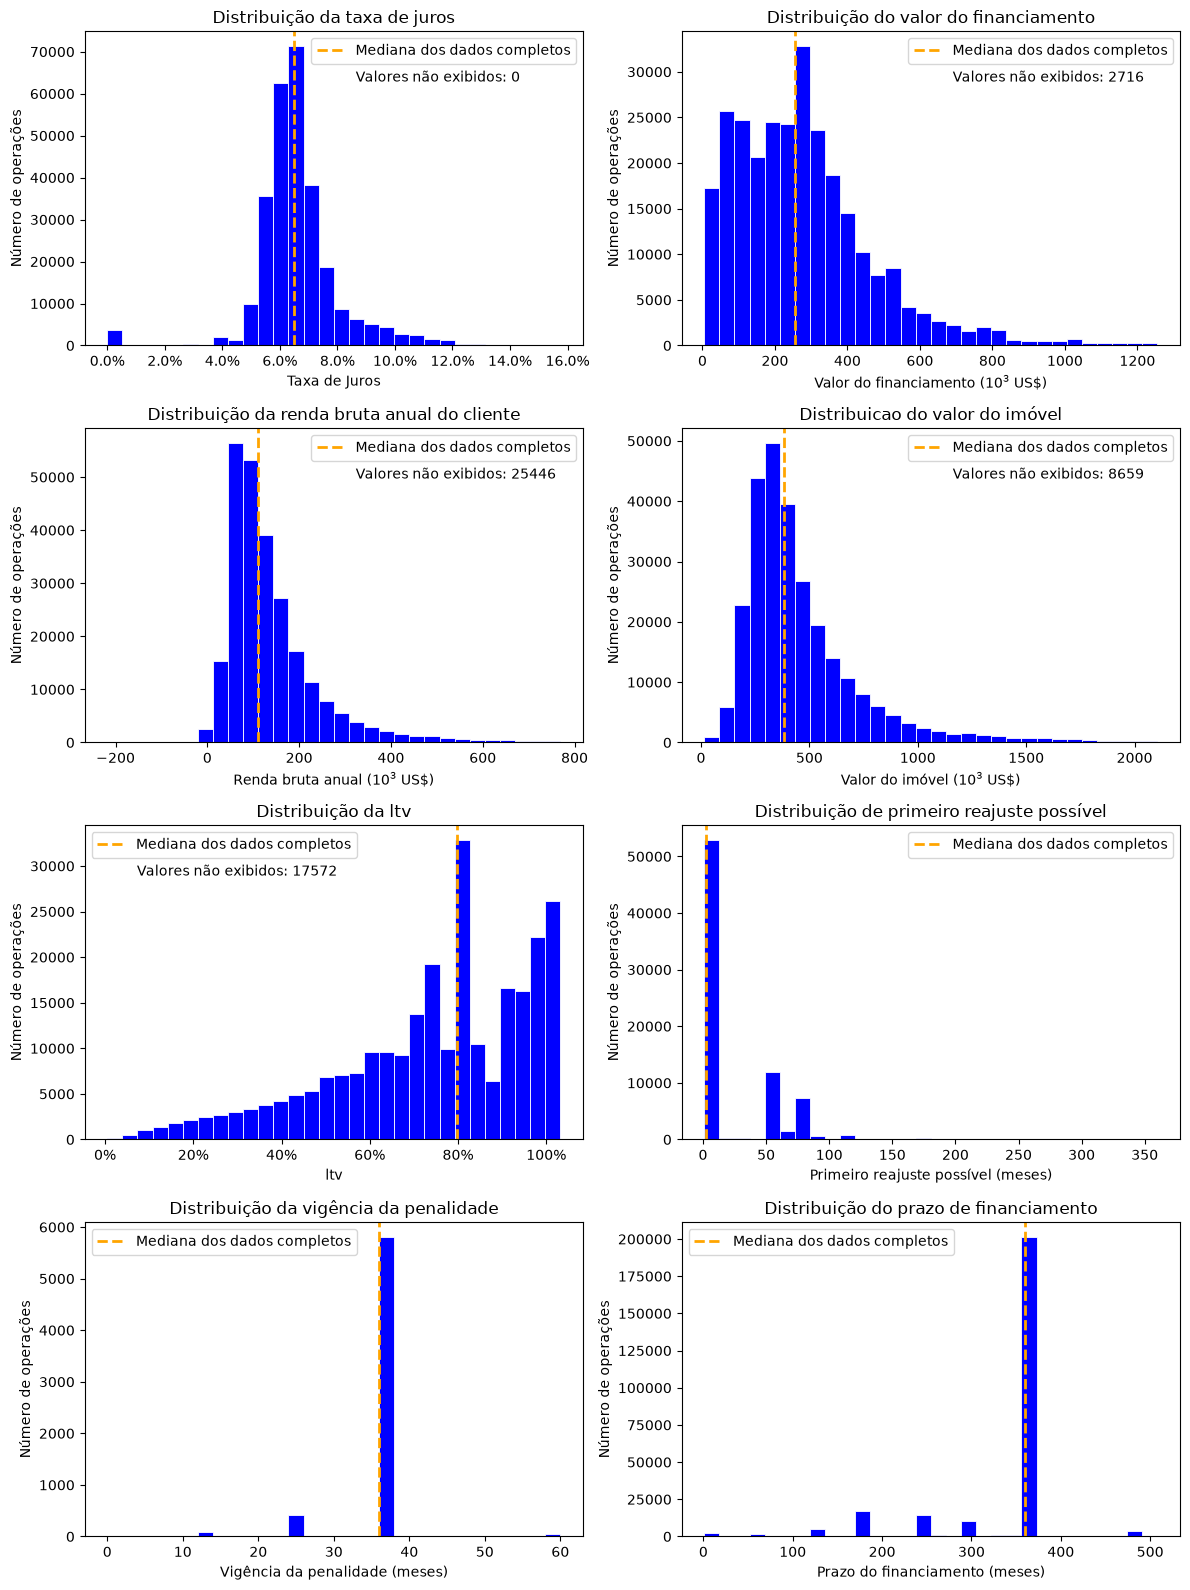

In [21]:
fig = plt.figure(figsize=(12,16))

ax1 = fig.add_subplot(421)

interest_rate = df_analise["interest_rate"]

hist1 = ax1.hist(interest_rate, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax1.set_ylabel("Número de operações")
ax1.set_xlabel("Taxa de Juros")
ax1.xaxis.set_major_formatter(PercentFormatter(100))
ax1.set_title("Distribuição da taxa de juros")
ax1.axvline(interest_rate.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax1.legend()

ax1.text(0.544, 0.84, f"Valores não exibidos: {0}", transform=ax1.transAxes)


ax2 = fig.add_subplot(422)

loan_amount = df_analise["loan_amount"]
inferior, superior = loan_amount.quantile([0, 0.99])

ax2.hist(loan_amount.loc[loan_amount.between(inferior, superior)]/1000, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax2.set_ylabel("Número de operações")
ax2.set_xlabel("Valor do financiamento ($10^3$ US\\$)")
ax2.set_title("Distribuição do valor do financiamento")
ax2.axvline(loan_amount.median()/1000, ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax2.legend()

ax2.text(0.544, 0.84, f"Valores não exibidos: {len(loan_amount)-len(loan_amount.loc[loan_amount.between(inferior, superior)])}", transform=ax2.transAxes)


ax3 = fig.add_subplot(423)

income = df_analise["income"]
inferior, superior = income.quantile([0, 0.99])

ax3.hist(income.loc[income.between(inferior, superior)], bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax3.set_ylabel("Número de operações")
ax3.set_xlabel("Renda bruta anual ($10^3$ US\\$)")
ax3.set_title("Distribuição da renda bruta anual do cliente")
ax3.axvline(income.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax3.legend()

ax3.text(0.544, 0.84, f"Valores não exibidos: {len(income)-len(income.loc[income.between(inferior, superior)])}", transform=ax3.transAxes)


ax4 = fig.add_subplot(424)

property_value = df_analise["property_value"]
inferior, superior = property_value.quantile([0, 0.99])

ax4.hist(property_value.loc[property_value.between(inferior, superior)]/1000, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax4.set_ylabel("Número de operações")
ax4.set_xlabel("Valor do imóvel ($10^3$ US\\$)")
ax4.set_title("Distribuicao do valor do imóvel")
ax4.axvline(property_value.median()/1000, ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax4.legend()

ax4.text(0.544, 0.84, f"Valores não exibidos: {len(property_value)-len(property_value.loc[property_value.between(inferior, superior)])}", transform=ax4.transAxes)


ax5 = fig.add_subplot(425)
loan_to_value_ratio = df_analise["loan_to_value_ratio"]
inferior, superior = loan_to_value_ratio.quantile([0, 0.99])

ax5.hist(loan_to_value_ratio.loc[loan_to_value_ratio.between(inferior, superior)], bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax5.set_ylabel("Número de operações")
ax5.set_xlabel("ltv")
ax5.xaxis.set_major_formatter(PercentFormatter(100))
ax5.set_title("Distribuição da ltv")
ax5.axvline(loan_to_value_ratio.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax5.legend()

ax5.text(0.105, 0.84, f"Valores não exibidos: {len(loan_to_value_ratio)-len(loan_to_value_ratio.loc[loan_to_value_ratio.between(inferior, superior)])}", transform=ax5.transAxes)

ax6 = fig.add_subplot(426)
intro_rate_period = df_analise["intro_rate_period"]

ax6.hist(intro_rate_period, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax6.set_ylabel("Número de operações")
ax6.set_xlabel("Primeiro reajuste possível (meses)")
ax6.set_title("Distribuição de primeiro reajuste possível")
ax6.axvline(intro_rate_period.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax6.legend()

ax7 = fig.add_subplot(427)
prepayment_penalty_term = df_analise["prepayment_penalty_term"]

ax7.hist(prepayment_penalty_term, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax7.set_ylabel("Número de operações")
ax7.set_xlabel("Vigência da penalidade (meses)")
ax7.set_title("Distribuição da vigência da penalidade")
ax7.axvline(prepayment_penalty_term.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax7.legend()

ax8 = fig.add_subplot(428)
loan_term = df_analise["loan_term"]

ax8.hist(loan_term, bins=30, color="blue", edgecolor="white", linewidth=0.6)
ax8.set_ylabel("Número de operações")
ax8.set_xlabel("Prazo do financiamento (meses)")
ax8.set_title("Distribuição do prazo de financiamento")
ax8.axvline(loan_term.median(), ymin=0, color="orange", linestyle="--", label="Mediana dos dados completos", linewidth=2)
ax8.legend()

fig.tight_layout()
plt.show()

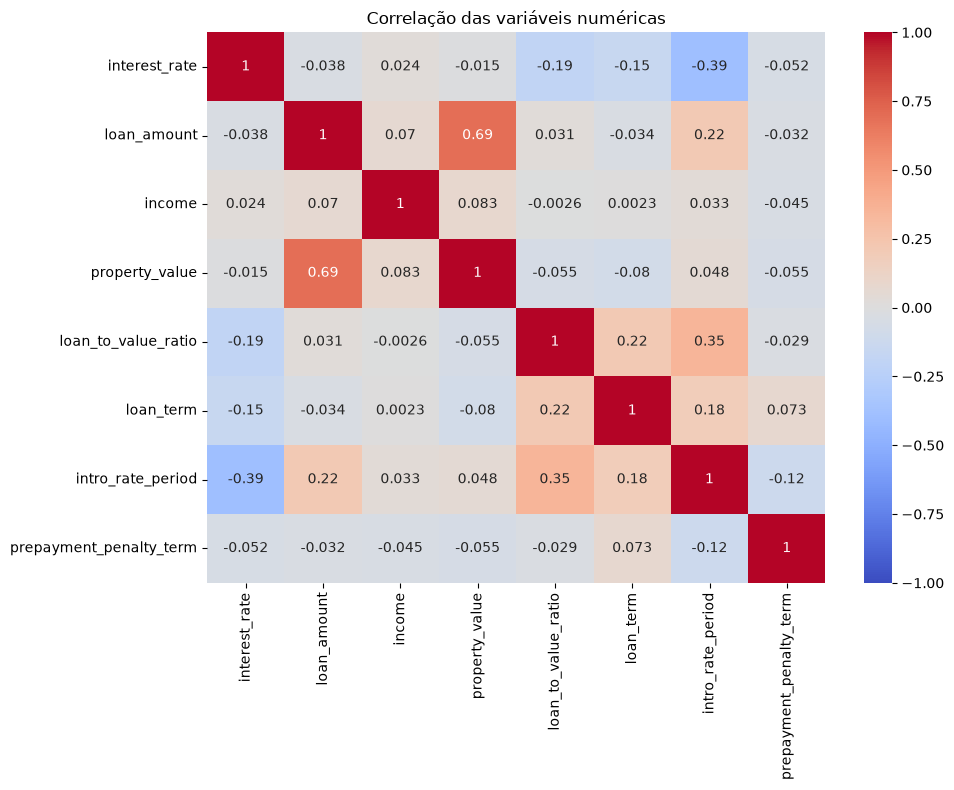

In [22]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot()

norm = mcolors.CenteredNorm()

sns.heatmap(df_analise[colunas_numericas].corr(), ax=ax, annot=True, cmap="coolwarm", norm=norm)
ax.set_title("Correlação das variáveis numéricas")
plt.tight_layout()
plt.show()

A matriz de correlação das variáveis numéricas revela os seguintes pontos:

- **Valor do financiamento e valor do imóvel:** Apresentam a maior correlação positiva observada, com coeficiente de 0,69. Essa associação indica que imóveis de maior valor tendem a estar relacionados a financiamentos de maior valor.

- **Taxa de juros e CLTV:** Apresentam correlação negativa fraca, de −0,19. O resultado indica uma relação linear pouco acentuada.

- **Taxa de juros e prazo do financiamento:** Apresentam correlação negativa fraca, de −0,15. Na amostra analisada, prazos maiores tendem a estar associados a taxas de juros ligeiramente menores.

- **Taxa de juros e primeiro reajuste possível:** Apresentam correlação negativa de -0,39, maior magnitude de correlação  com a taxa de juros. Indica que financiamentos com maior prazo de mudança da taxa de taxa de juros tendem a apresentar menores taxas de juros.

- **Taxa de juros e demais variáveis:** As correlações com valor do financiamento (−0,038), renda anual (0,024) e valor do imóvel (−0,015) estão próximas de zero, indicando pouca associação linear.

- **LTV e prazo do financiamento:** Apresentam correlação positiva fraca de 0,22, sugerindo que operações com maior proporção de dívida em relação ao valor das garantias tendem a apresentar prazos maiores.

- **Primeiro reajuste possível e demais variáveis:** O prazo de mudança da taxa de juros apresenta correlação levemente positiva com o valor do financiamento (0,22) com razão entre o valor do financiamento e o valor do imóvel (0,35) e o prazo do financiamento (0,18) e levemente negativa com a vigência de penalidade (-0.12). Esses valores encontrados indicam uma leve correlação linear, mas ainda baixa.

Nenhuma das variáveis numéricas apresenta correlação linear forte com a taxa de juros. Entretanto, correlações próximas de zero não descartam relações não lineares ou efeitos decorrentes da combinação de variáveis. Portanto, esses resultados, isoladamente, não justificam a exclusão de variáveis do modelo. A interpretação também deve considerar que valores extremos podem influenciar os coeficientes de Pearson

**Variaveis categóricas**

In [23]:
colunas_categoricas = ["loan_type", "loan_purpose", "lien_status", "occupancy_type", "construction_method",
                        "total_units", "conforming_loan_limit", "business_or_commercial_purpose", "balloon_payment", 
                        "interest_only_payment", "negative_amortization", "other_nonamortizing_features",
                        "open-end_line_of_credit", "reverse_mortgage", "county_code", "lei"]

df_analise[colunas_categoricas].describe()

,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,total_units,conforming_loan_limit,business_or_commercial_purpose,balloon_payment,interest_only_payment,negative_amortization,other_nonamortizing_features,open-end_line_of_credit,reverse_mortgage,county_code,lei
count,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138,278138
unique,4,6,2,3,2,9,3,3,3,3,3,3,3,3,101,962
top,1,1,1,1,1,1,C,2,2,2,2,2,2,2,37183,549300SHE1JTCOWBP090
freq,207079,148025,219011,248176,265851,275695,269244,261233,265098,250070,277981,276605,222007,277095,32177,27571


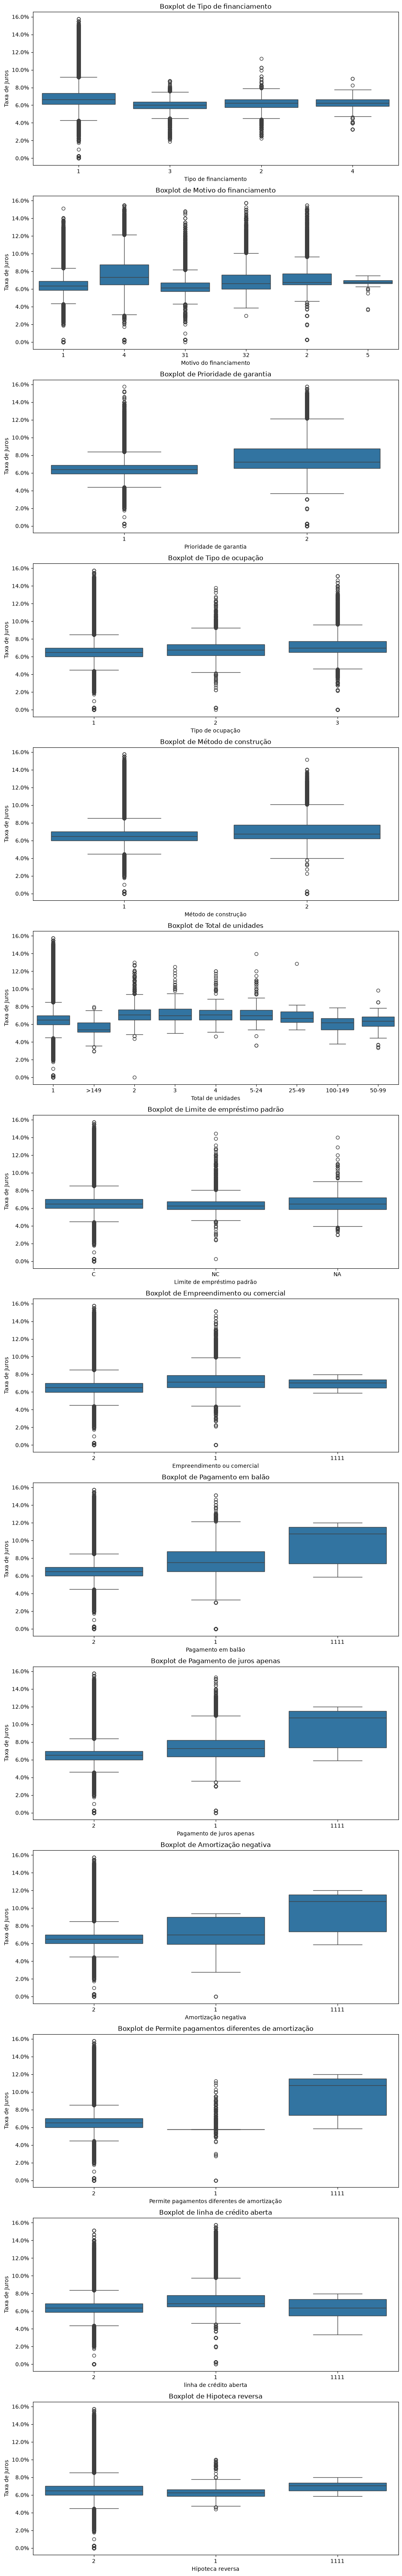

In [24]:
nomes = {
    "loan_type": "Tipo de financiamento",
    "loan_purpose": "Motivo do financiamento",
    "lien_status": "Prioridade de garantia",
    "occupancy_type": "Tipo de ocupação",
    "construction_method": "Método de construção",
    "total_units": "Total de unidades",
    "conforming_loan_limit": "Limite de empréstimo padrão",
    "business_or_commercial_purpose": "Empreendimento ou comercial",
    "balloon_payment": "Pagamento em balão",
    "interest_only_payment": "Pagamento de juros apenas",
    "negative_amortization": "Amortização negativa",
    "other_nonamortizing_features": "Permite pagamentos diferentes de amortização",
    "open-end_line_of_credit": "linha de crédito aberta",
    "reverse_mortgage": "Hipoteca reversa"
}

fig, ax = plt.subplots(nrows=len(nomes), ncols=1, figsize=(12,6*len(nomes)))

for i, feature in enumerate(nomes.keys()):
    sns.boxplot(data=df_analise, x=feature, y="interest_rate", ax=ax[i])
    ax[i].yaxis.set_major_formatter(PercentFormatter(100))
    ax[i].set_ylabel("Taxa de Juros")
    ax[i].set_xlabel(nomes[feature])
    ax[i].set_title(f"Boxplot de {nomes[feature]}")


A análise descritiva das variáveis categóricas e dos boxplots da taxa de juros revela os seguintes pontos:

- **Tipo de financiamento:** os financiamentos convencionais (1) representam 74,45% dos registros e apresentam mediana e dispersão central das taxas superiores às demais modalidades. Os financiamentos garantidos pelo Departamento de Assuntos de Veteranos — VA (3) apresentam a menor mediana.

- **Motivo do financiamento:** a compra de imóveis (1) representa 53,22% das operações. A categoria de outras finalidades (4) apresenta a maior mediana e maior dispersão central das taxas, enquanto compra e refinanciamento sem retirada de recursos (31) apresentam medianas menores.

- **Prioridade da garantia:** operações com garantia de primeira prioridade (1) representam 78,74% dos registros. Financiamentos com garantia subordinada (2) apresentam mediana mais elevada e maior dispersão central das taxas de juros.

- **Tipo de ocupação:** imóveis destinados à residência principal (1) representam 89,23% dos registros. As medianas das taxas aumentam entre residência principal, segunda residência (2) e imóvel para investimento (3), embora exista sobreposição entre as distribuições.

- **Método de construção:** imóveis construídos no local (1) representam 95,58% dos registros. Habitações manufaturadas (2) apresentam mediana mais elevada e maior dispersão central das taxas de juros.

- **Total de unidades:** imóveis com uma unidade residencial representam 99,12% dos registros, indicando forte concentração nessa categoria. Os grupos de duas a quatro unidades e de 5–24 unidades apresentam medianas superiores à categoria de uma unidade, enquanto o grupo com mais de 149 unidades apresenta a menor mediana. Não se observa uma relação crescente entre número de unidades e taxa de juros.

- **Enquadramento no limite de valor:** operações classificadas como conformes ao limite aplicável (C) representam 96,80% dos registros. As distribuições apresentam ampla sobreposição, com mediana ligeiramente menor no grupo não conforme (NC) e maior dispersão central no grupo não aplicável (NA).

- **Finalidade comercial ou empresarial:** operações que não possuem finalidade predominantemente comercial ou empresarial (2) representam 93,92% dos registros. Operações com essa finalidade (1) apresentam mediana mais elevada e maior dispersão central das taxas.

- **Pagamento balão:** operações sem previsão de pagamento balão (2) representam 95,31% dos registros. Financiamentos que incluem essa característica (1) apresentam mediana mais elevada e maior dispersão central das taxas de juros.

- **Pagamento apenas de juros:** operações sem previsão contratual de pagamentos apenas de juros (2) representam 89,91% dos registros. A presença dessa característica (1) está associada a mediana mais elevada e maior dispersão central das taxas.

- **Amortização negativa:** operações sem previsão de amortização negativa (2) representam 99,94% dos registros. A categoria que admite essa condição (1) apresenta mediana superior e maior dispersão central das taxas. Entretanto, sua baixa representatividade exige cautela na interpretação.

- **Outras características não amortizantes:** operações sem outras condições que permitam pagamentos não integralmente amortizantes (2) representam 99,45% dos registros. A categoria que apresenta essas características (1) possui mediana inferior e intervalo interquartil visualmente bastante reduzido, apesar da presença de valores afastados da região central.

- **Linha de crédito aberta:** operações que não são linhas de crédito abertas (2) representam 79,82% dos registros. As operações classificadas como linhas de crédito abertas (1) apresentam mediana mais elevada e maior dispersão central das taxas de juros.

- **Hipoteca reversa:** operações que não são hipotecas reversas (2) representam 99,63% dos registros. As hipotecas reversas (1) apresentam mediana ligeiramente menor e menor dispersão central das taxas. A forte concentração na categoria predominante limita a comparação entre os grupos.

- **Localização do imóvel:** a variável `county_code` apresenta 101 valores distintos. O código mais frequente, `37183`, reúne 32.177 operações, correspondentes a 11,57% dos registros. Essa contagem descreve os valores registrados na coluna e não deve ser interpretada automaticamente como o número de condados, pois pode incluir códigos especiais.

- **Instituição financeira:** a variável `lei` apresenta 962 identificadores distintos. A instituição identificada por `549300SHE1JTCOWBP090` concentra 27.571 operações, equivalentes a 9,91% dos registros. Essa variável apresenta elevada cardinalidade; a tabela de frequências, isoladamente, não permite concluir como as taxas variam entre instituições.

Nos boxplots de pagamento balão, pagamento apenas de juros, amortização negativa e outras características não amortizantes, a categoria `1111` apresenta medianas superiores às categorias `1` e `2`. Esse código corresponde à isenção de reporte da informação e não equivale à ausência da característica contratual.

As diferenças observadas descrevem associações entre as categorias e as taxas de juros. A concentração dos registros em determinadas categorias exige cautela na interpretação dos grupos menos representados.
## Implementação dos modelos de machine learning

In [25]:
# Seed fixa para garantir reprodutibilidade
rs = 42

# Separando variáveis numéricas
features_numericas = ["loan_amount", "income", "property_value", "loan_to_value_ratio", "loan_term",
                      "intro_rate_period", "prepayment_penalty_term"]

# Separando variáveis indicadoras
features_indicadoras = ["income_not_available", "property_value_not_available", "property_value_exempt",
                        "loan_to_value_ratio_not_available", "loan_to_value_ratio_exempt", "loan_term_not_available",
                        "loan_term_exempt", "intro_rate_period_not_available", "intro_rate_period_exempt", 
                        "prepayment_penalty_term_not_available", "prepayment_penalty_term_exempt"]

# Separando variáveis categóricas
features_categoricas = ["loan_type", "loan_purpose", "lien_status", "occupancy_type", "construction_method",
                        "total_units", "conforming_loan_limit", "business_or_commercial_purpose", "balloon_payment",
                        "interest_only_payment", "negative_amortization", "other_nonamortizing_features", 
                        "open-end_line_of_credit", "reverse_mortgage", "county_code"]

# Separando a variável de instituição
instituicao = ["lei"]

# Separando a variável alvo
target = "interest_rate"

# Separando os conjuntos de análise 
X = df_analise[features_numericas + features_categoricas + features_indicadoras + instituicao]
Y = df_analise[target]

# Separando conjuntos de treino e teste dos modelos
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=rs)

In [26]:
def avaliar_busca(busca, nome, X_teste, y_teste):
    """Compara treino, validação e teste da configuração vencedora."""
    i = busca.best_index_
    resultados = busca.cv_results_
    y_previsto = busca.predict(X_teste)

    metricas = {
        "MAE": ("mae", mean_absolute_error, -1),
        "RMSE": ("rmse", root_mean_squared_error, -1),
        "R2": ("r2", r2_score, 1),
    }

    linhas = []

    for metrica, (chave, funcao, sinal) in metricas.items():
        linhas.append({
            "Modelo": nome,
            "Métrica": metrica,
            "Treino CV": sinal * resultados[f"mean_train_{chave}"][i],
            "DP Treino": resultados[f"std_train_{chave}"][i],
            "Validação CV": sinal * resultados[f"mean_test_{chave}"][i],
            "DP Validação": resultados[f"std_test_{chave}"][i],
            "Teste": funcao(y_teste, y_previsto),
        })

    return pd.DataFrame(linhas)

In [27]:
def resumir_resultados_teste(y_true, y_pred):
    """
    Cria um resumo das principais métricas usadas para avaliar o modelo
    """
    residuos = y_true-y_pred
    erro_absoluto = abs(residuos)

    resumo = {
    "MAE": erro_absoluto.mean(), # Média do erro absoluto
    "RMSE": root_mean_squared_error(y_true, y_pred), # Raiz quadrada do erro quadrático
    "R2": r2_score(y_true, y_pred),
    "MedAE": erro_absoluto.median(), # Mediana do erro absoluto
    "P90_erro": erro_absoluto.quantile(0.90), # Percentil 90
    "P99_erro": erro_absoluto.quantile(0.99), # Percentil 99
    "vies": residuos.mean() # Viés médio dos erros
}

    return pd.Series(resumo)

In [28]:
def grafico_resultados(y_true, y_pred, y_ref):
    """
    Cria uma figura resumo com os seguintes gráficos:
    1 - Distribuição de resíduos do modelo
    2 - Soma acumulada do erro absoluto
    3 - Densidade de dispersão da relação Previsão x Resíduos
    4 - Densidade de dispersão da relação Previsão x Observação
    """

    residuos = y_true - y_pred
    erro_absoluto = abs(residuos)


    fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

    # 1 - Distribuição de resíduos do modelo
    ax[0][0].set(xlabel="Resíduo (p.p.)", ylabel="Número de operações", title="Distribuição de resíduos")
    ax[0][0].hist(y_true-y_ref, bins=30, label="Resíduos da referência", alpha=0.7, color="gray")
    ax[0][0].hist(residuos, bins=30, label="Resíduos do modelo")
    ax[0][0].legend()

    # 2 - Soma acumulada do erro absoluto
    erro_absoluto_ordenado = np.sort(erro_absoluto)
    fracao = np.arange(1, len(erro_absoluto_ordenado)+1)/len(erro_absoluto_ordenado)
    ax[0][1].set(xlabel="Erro absoluto (p.p.)", ylabel="Proporção de operações", title="Distribuição acumulada do erro absoluto")
    ax[0][1].step(np.r_[0, erro_absoluto_ordenado], np.r_[0, fracao], where="post", label="Erro absoluto acumulado do modelo")
    ax[0][1].yaxis.set_major_formatter(PercentFormatter(1))

    # 3 - Densidade de dispersão da relação Previsão x Resíduos
    ax[1][0].set(xlabel="Taxa de juros prevista", ylabel="Resíduo (p.p.)", title="Previsão $\\times$ Resíduos")
    ax[1][0].xaxis.set_major_formatter(PercentFormatter(100))
    densidade_pxr = ax[1][0].hexbin(y_pred, residuos, gridsize=30, mincnt=1, bins="log", cmap="winter")
    ax[1][0].axhline(0, xmin=0, xmax=1, linestyle="--", color="black", label="previsão exata")
    ax[1][0].legend()
    fig.colorbar(densidade_pxr, ax=ax[1][0], label="Número de operações")

    # 4 - Densidade de dispersão da relação Previsão x Observação
    minimo = min(y_true.min(), y_pred.min())
    maximo = max(y_true.max(), y_pred.max())
    limites = [minimo, maximo]
    ax[1][1].set(xlabel="Taxa de juros prevista", ylabel="Taxa de juros observada", title="Previsão $\\times$ Observação")
    ax[1][1].xaxis.set_major_formatter(PercentFormatter(100))
    ax[1][1].yaxis.set_major_formatter(PercentFormatter(100))
    densidade_pxo = ax[1][1].hexbin(y_pred, y_true, gridsize=30, mincnt=1, bins="log", cmap="winter")
    ax[1][1].plot(limites, limites, linestyle="--", color="black", label="Previsão exata")
    ax[1][1].legend()
    fig.colorbar(densidade_pxo, ax=ax[1][1], label="Número de operações")

    plt.tight_layout()
    plt.show()    


In [29]:
def criar_pipeline(modelo, linear=False):
    """
    Cria a pipeline de para preparação e pré-processamento dos dados para implementação dos modelos de ML
    """
    # Inserção de dados faltantes e padronização das variáveis numéricas
    etapas_numericas = [
        ("imputador", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("escala", StandardScaler())
    ]
    
    # Etapas de pré-processamento 
    preprocessamento = ColumnTransformer([
        ("numericas", Pipeline(etapas_numericas), features_numericas),
        ("categoricas", OneHotEncoder(
            handle_unknown="ignore", 
            drop="first" if linear else None, 
            sparse_output=True), features_categoricas),
        ("indicadoras", "passthrough", features_indicadoras),
        ("instituicao", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=100,
            max_categories=200,
            sparse_output=True,
            drop="first" if linear else None
        ), instituicao)
    ])

    return Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", modelo)
    ])

Utilizamos um modelo de referência que prevê, para todas as operações, a mediana da taxa de juros observada no conjunto de treino. Essa comparação permite avaliar o ganho dos modelos em relação a uma previsão constante.

In [30]:
# Treinamento do modelo de referência
dummy = DummyRegressor(strategy="median")
dummy.fit(X_train, y_train)

y_dummy = dummy.predict(X_test)
y_dummy

array([6.5, 6.5, 6.5, ..., 6.5, 6.5, 6.5], shape=(55628,))

Para cada um dos modelos vamos fazer a otimização dos hiperparâmetros utilizando os seguintes algoritmos:
- XGBoost - Vamos utiizar uma busca bayesiana (BayesSearch), buscando sem um custo computacional elevado uma configuração satisfatória para o modelo.
- Regressão Linear - Como este é um modelo mais simples e temos poucas configurações possíveis, vamos utilizar a busca em grade (GridSearch) para determinar a melhor configuração possível do modelo.

In [31]:
# Inicialização da pipeline para o modelo XGBoost
pipe_xgb = criar_pipeline(XGBRegressor(
                            objective = "reg:squarederror",
                            tree_method="hist",
                            random_state=rs, 
                            n_jobs=4))

# Espaço de hiperparâmetros a serem analisados
espaco_parametros = {
    "modelo__n_estimators": Integer(50, 1000),
    "modelo__learning_rate": Real(0.01, 0.3, prior="log-uniform"),
    "modelo__max_depth": Integer(3, 10),
    "modelo__min_child_weight": Integer(1, 10),
    "modelo__subsample": Real(0.5, 1.0),
    "modelo__colsample_bytree": Real(0.5, 1.0),
    "modelo__gamma": Real(0, 5),
    "modelo__reg_lambda": Real(0.01, 100.0, prior="log-uniform")
}

# Métricas de avaliação do modelo
scoring={"mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"}

cv = KFold(n_splits=5, shuffle=True, random_state=rs)

# Inicialização do método de busca
otimizador_xgb = BayesSearchCV(
    estimator=pipe_xgb,
    search_spaces=espaco_parametros,
    n_iter=30, 
    cv=cv, 
    scoring=scoring,
    refit="mae",
    random_state=rs,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Treinamento e otimização do modelo
otimizador_xgb.fit(X_train, y_train)

# Análise dos resultados obtidos
resultados = pd.DataFrame(otimizador_xgb.cv_results_)

colunas = [
    "params",
    "mean_test_mae",
    "mean_test_rmse",
    "mean_test_r2"
]

resultados[colunas]

,params,mean_test_mae,mean_test_rmse,mean_test_r2
0,{'modelo__colsample_bytree': 0.705051979426657...,-0.42,-0.61,0.84
1,{'modelo__colsample_bytree': 0.918694177776642...,-0.44,-0.65,0.81
2,{'modelo__colsample_bytree': 0.722416256150575...,-0.47,-0.69,0.79
3,{'modelo__colsample_bytree': 0.906197994178681...,-0.42,-0.61,0.84
4,{'modelo__colsample_bytree': 0.899776720803586...,-0.40,-0.58,0.85
5,{'modelo__colsample_bytree': 0.867014008992784...,-0.53,-0.78,0.73
6,{'modelo__colsample_bytree': 0.808539679251158...,-0.41,-0.59,0.85
7,{'modelo__colsample_bytree': 0.771701533845156...,-0.43,-0.64,0.82
8,{'modelo__colsample_bytree': 0.977738993154964...,-0.41,-0.60,0.84
9,{'modelo__colsample_bytree': 0.501815153627371...,-0.43,-0.63,0.83


In [32]:
# Melhor modelo da busca
melhor_modelo_xgb = otimizador_xgb.best_estimator_

# Predição do conjunto de testes
y_pred_xgb = melhor_modelo_xgb.predict(X_test)

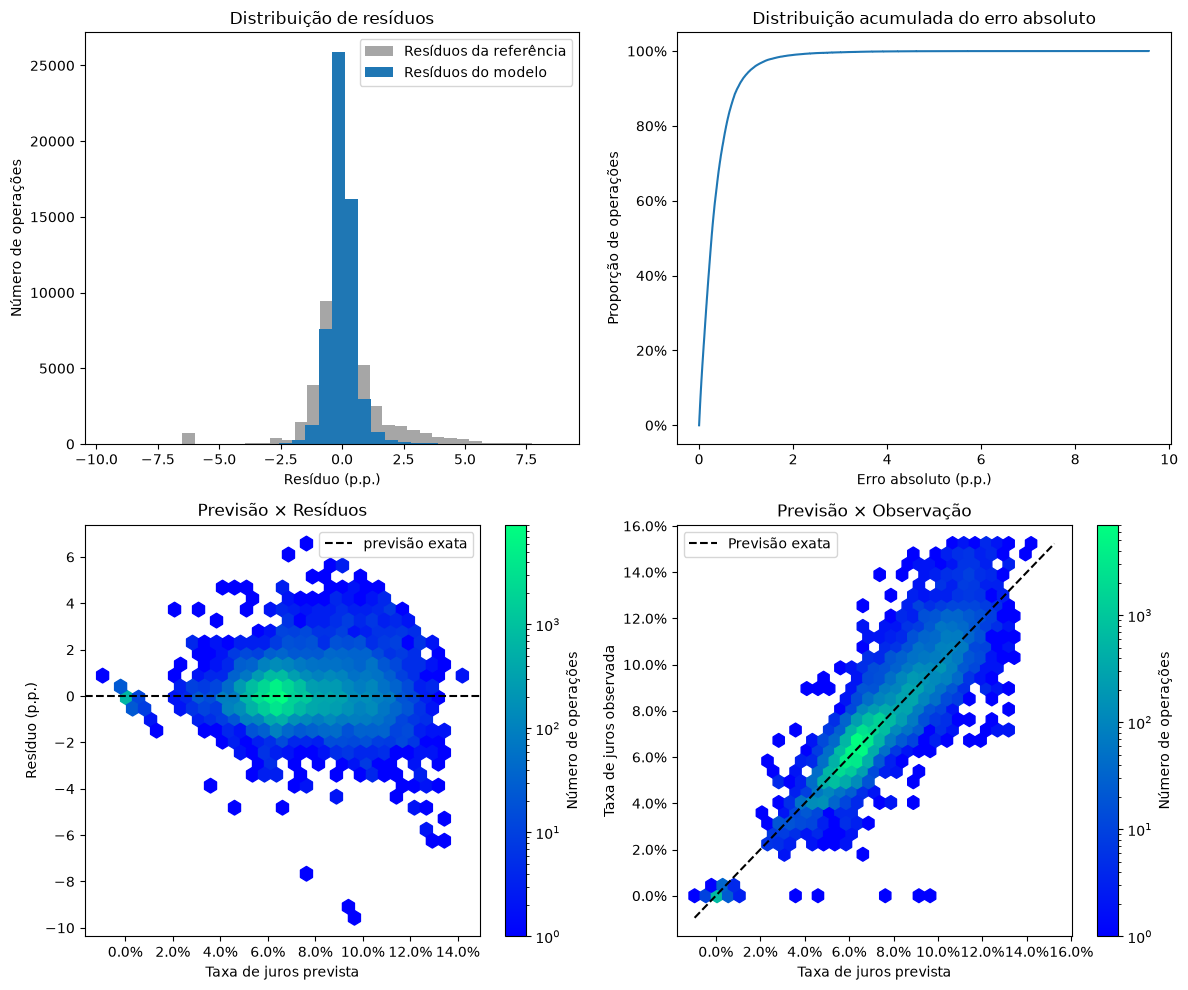

In [33]:
# Análise visual dos resultados do modelo
grafico_resultados(y_test, y_pred_xgb, y_dummy)

Pela análise visual inicial do modelo, podemos concluir que:
- A distribuição dos resíduos está centrada em zero e é claramente mais estreita que o modelo de referência.
- A distribuição acumulada do erro absoluto se aproxima de 100% em valores próximos de 2 pontos percentuais (p.p.). Isso indica que a maioria das previsões apresentam erro abaixo desse valor.
- As distribuições de dispersão de previsão x resíduos e previsão x observação seguem a tendência das respectivas linhas de resultados exatos.


In [34]:
# Inicialização da pipeline para o modelo de regressão linear
pipe_linear = criar_pipeline(LinearRegression(positive=False), linear=True)

# Espaço de hiperparâmetros a serem analisados
espaco_parametros = {
    "modelo__fit_intercept": [True, False]
}

# Métricas de avaliação do modelo
scoring={"mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"}

cv = KFold(n_splits=5, shuffle=True, random_state=rs)

# Inicialização do método de busca
otimizador_linear = GridSearchCV(
    estimator=pipe_linear,
    param_grid=espaco_parametros,
    cv=cv, 
    scoring=scoring,
    refit="mae",
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Treinamento e otimização do modelo
otimizador_linear.fit(X_train, y_train)

# Análise dos resultados obtidos
resultados = pd.DataFrame(otimizador_linear.cv_results_)

colunas = [
    "params",
    "mean_test_mae",
    "mean_test_rmse",
    "mean_test_r2"
]

resultados[colunas]

,params,mean_test_mae,mean_test_rmse,mean_test_r2
0,{'modelo__fit_intercept': True},-0.73,-1.17,0.41
1,{'modelo__fit_intercept': False},-0.73,-1.18,0.40


In [35]:
# Seleção do melhor modelo de regressão linear
melhor_modelo = otimizador_linear.best_estimator_

# Predição do conjunto de testes
y_pred_linear = melhor_modelo.predict(X_test)

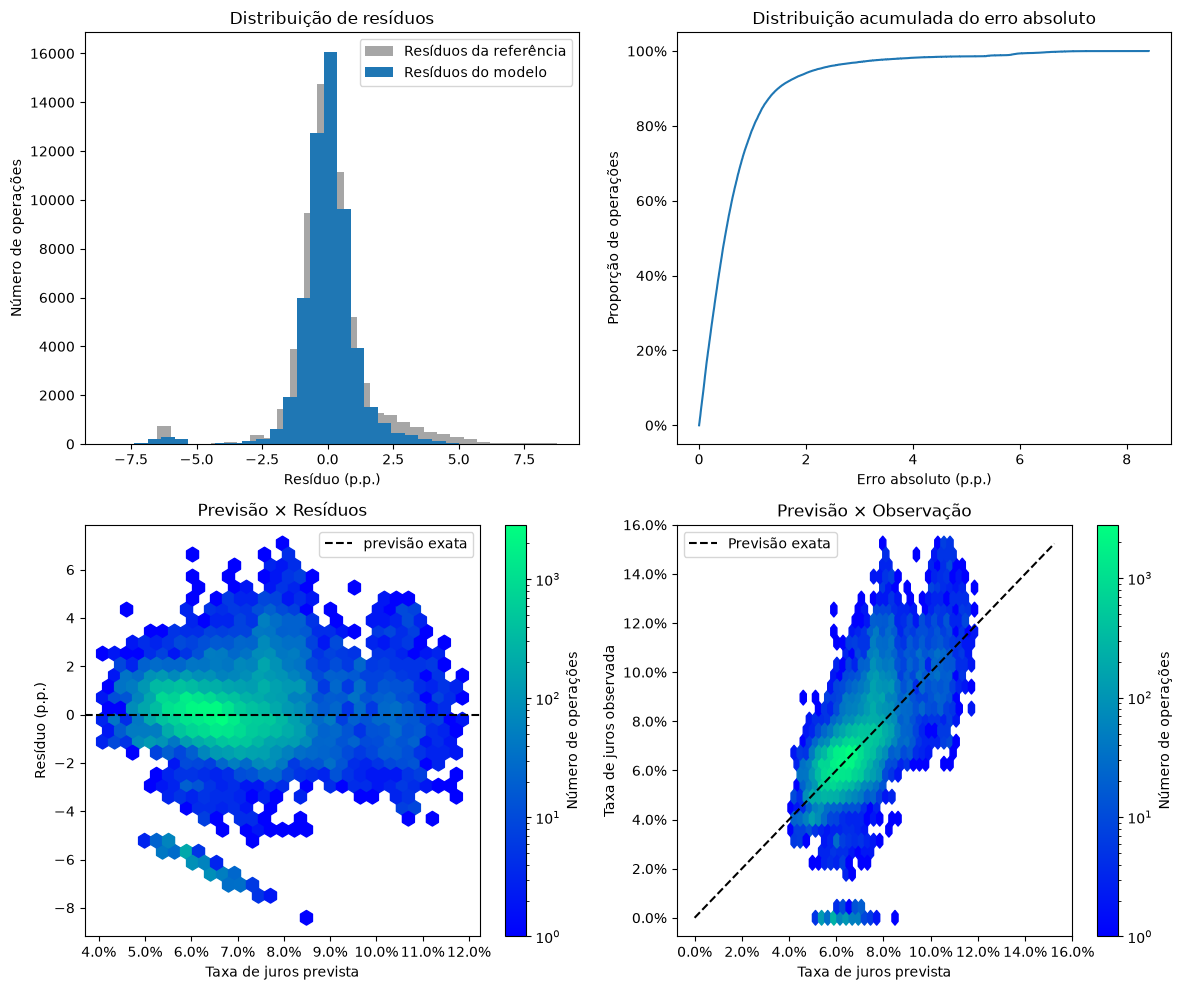

In [36]:
# Análise visual dos resultados do modelo de regressão linear
grafico_resultados(y_test, y_pred_linear, y_dummy)

Pela análise visual inicial do modelo, podemos concluir que:
- A distribuição dos resíduos está centrada em zero, é claramente mais estreita que o modelo de referência mas parece mais larga que o modelo XGBoost, indicando uma performance pior nos testes.
- Observamos uma distribuição acumulada do erro absoluto mais suave, se aproximando de 100% em uma região próxima de 6 p.p.. Isso mostra erros maiores que os observados com o modelo XGBoost.
- Assim como o modelo de XGBoost, as distribuições de dispersão de previsão x resíduos e previsão x observação seguem a tendência das respectivas linhas de resultados exatos, apesar de ser possível perceber uma dispersão mais larga e menos precisa para valores de limite (próximos de zero ou de 15)

In [37]:
buscas = {
    "XGBoost": otimizador_xgb,
    "Linear": otimizador_linear,
}

resumo_treinamento = pd.concat(
    [
        avaliar_busca(busca, nome, X_test, y_test)
        for nome, busca in buscas.items()
    ],
    ignore_index=True,
).set_index(["Modelo", "Métrica"])

resumo_treinamento.style.format(precision=4)

A comparação entre os resultados de treino e validação permite avaliar a diferença de desempenho entre as observações utilizadas no ajuste e aquelas reservadas para avaliação. Os resultados de treino e validação são apresentados como média $\pm$ desvio-padrão entre as cinco dobras da validação cruzada.

XGBoost: o MAE aumenta de 0,3070 p.p. no treino para 0,3815 p.p. na validação, enquanto o RMSE passa de 0,4314 para 0,5659 p.p. Esses aumentos, de aproximadamente 24% e 31%, indicam uma diferença entre o ajuste aos dados de treinamento e o desempenho em observações não utilizadas nesse ajuste, compatível com algum grau de sobreajuste. Apesar disso, os erros de validação permanecem inferiores aos da regressão linear. Os pequenos desvios-padrão indicam pouca variação de desempenho entre as dobras utilizadas.

Regressão linear: os resultados de treino e validação são próximos, com MAE de 0,7265 e 0,7281 p.p., respectivamente. Essa proximidade sugere pouca evidência de sobreajuste. Entretanto, os erros relativamente elevados, inclusive no treinamento, sugerem uma limitação da especificação linear adotada para representar os padrões presentes nos dados. Assim, a pequena diferença entre treino e validação não implica, por si só, maior capacidade preditiva.

In [38]:
# Calculo das métricas de comparação de cada modelo
resumo_completo = pd.DataFrame(
    {
        "Referência": resumir_resultados_teste(y_test, y_dummy),
        "XGBoost": resumir_resultados_teste(y_test, y_pred_xgb),
        "Linear": resumir_resultados_teste(y_test, y_pred_linear)
    }
)
resumo_completo

,Referência,XGBoost,Linear
MAE,0.92,0.38,0.73
RMSE,1.52,0.57,1.17
R2,-0.01,0.86,0.40
MedAE,0.51,0.26,0.48
P90_erro,2.25,0.81,1.48
P99_erro,6.50,2.02,5.84
vies,0.14,0.01,0.01


No conjunto de teste, ambos os modelos apresentam melhorias em relação ao modelo de referência, com vantagem para o XGBoost.

- **XGBoost:** apresenta MAE de 0,38 p.p. e RMSE de 0,57 p.p., correspondendo a reduções de aproximadamente 59% e 63% em relação à referência. O erro absoluto mediano é de 0,26 p.p., indicando que aproximadamente metade das previsões apresenta erro absoluto de até esse valor. Os percentis 90 e 99 são de 0,81 p.p. e 2,02 p.p., respectivamente: aproximadamente 90% e 99% das previsões apresentam erros absolutos até esses limites. Esses resultados mostram melhorias tanto nos erros típicos quanto na faixa dos erros mais elevados.

- **Regressão linear:** apresenta MAE de 0,73 p.p. e RMSE de 1,17 p.p., com reduções de aproximadamente 21\
% e 23% em relação ao Dummy. Entretanto, a redução do erro absoluto mediano é pequena, de 0,51 para 0,48 p.p. O percentil 99 permanece elevado, em 5,84 p.p., indicando que, apesar da melhora média, persistem erros expressivos em uma parcela das operações.

O $R^2$ de teste é de 0,86 para o XGBoost e de 0,40 para a regressão linear. Em relação à previsão constante da média das taxas no conjunto de teste, esses valores correspondem a reduções de aproximadamente 86% e 40% na soma dos erros quadráticos. Essa comparação reforça a maior capacidade preditiva do XGBoost na amostra avaliada.

Os dois modelos apresentam viés médio próximo de zero. Entretanto, erros positivos e negativos podem se compensar, de modo que esse resultado não garante erros pequenos nem ausência de tendências em grupos específicos de operações.

A proximidade entre as métricas de validação e teste indica consistência de desempenho na divisão de dados adotada. Considerando os menores erros e o melhor desempenho de validação, o XGBoost foi escolhido para a próxima etapa do projeto.